In [2]:
%pip install seaborn
#seabornをインストール

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#ライブラリをインポート
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#Cythonをインストール
%pip install Cython


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
#sklearnをインストール
import sklearn 
sklearn.set_config(display="text")


In [6]:
#線形モデルをインポート
%pip install scikit-learn
from sklearn.linear_model import LinearRegression as LR
%matplotlib inline


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [7]:
#学習データの読み込み
train = pd.read_csv("train.csv")
#検証用データの読み込み
test = pd.read_csv("test.csv")
#提出用サンプルデータの読み込み
sample = pd.read_csv("sample.csv", header=None)

#データ確認
train.head(5)

,datetime,y,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature
0,2013-11-18,90,月,0,厚切りイカフライ,NaN,NaN,NaN,NaN,快晴,--,19.8
1,2013-11-19,101,火,1,手作りヒレカツ,NaN,NaN,NaN,NaN,快晴,--,17.0
2,2013-11-20,118,水,0,白身魚唐揚げ野菜あん,NaN,NaN,NaN,NaN,快晴,--,15.5
3,2013-11-21,120,木,1,若鶏ピリ辛焼,NaN,NaN,NaN,NaN,快晴,--,15.2
4,2013-11-22,130,金,1,ビッグメンチカツ,NaN,NaN,NaN,NaN,快晴,--,16.1


In [8]:
test.head()

,datetime,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature
0,2014-10-1,水,1,メンチカツ,420.0,NaN,NaN,NaN,雨,0,20.2
1,2014-10-2,木,0,バーベキューチキン,415.0,NaN,NaN,NaN,曇,--,23.9
2,2014-10-3,金,0,豚肉のマスタード焼き,405.0,NaN,NaN,NaN,晴れ,--,28.7
3,2014-10-6,月,1,麻婆春雨,400.0,NaN,NaN,NaN,雨,0.5,21.5
4,2014-10-7,火,0,厚揚げ肉みそ炒め,430.0,NaN,NaN,NaN,晴れ,--,22.1


In [9]:
#データ分離用のフラグを立てる
train["fig"] =1
test["fig"] =0


In [10]:
#trainとtestを結合する
all_data = pd.concat([train,test],axis=0,sort=False)
all_data.head()

,datetime,y,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature,fig
0,2013-11-18,90.0,月,0,厚切りイカフライ,NaN,NaN,NaN,NaN,快晴,--,19.8,1
1,2013-11-19,101.0,火,1,手作りヒレカツ,NaN,NaN,NaN,NaN,快晴,--,17.0,1
2,2013-11-20,118.0,水,0,白身魚唐揚げ野菜あん,NaN,NaN,NaN,NaN,快晴,--,15.5,1
3,2013-11-21,120.0,木,1,若鶏ピリ辛焼,NaN,NaN,NaN,NaN,快晴,--,15.2,1
4,2013-11-22,130.0,金,1,ビッグメンチカツ,NaN,NaN,NaN,NaN,快晴,--,16.1,1


In [11]:
#欠損数、型を確認する
all_data.info()

<class 'pandas.DataFrame'>
Index: 247 entries, 0 to 39
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   datetime       247 non-null    str    
 1   y              207 non-null    float64
 2   week           247 non-null    str    
 3   soldout        247 non-null    int64  
 4   name           247 non-null    str    
 5   kcal           202 non-null    float64
 6   remarks        28 non-null     str    
 7   event          17 non-null     str    
 8   payday         12 non-null     float64
 9   weather        247 non-null    str    
 10  precipitation  247 non-null    str    
 11  temperature    247 non-null    float64
 12  fig            247 non-null    int64  
dtypes: float64(4), int64(2), str(7)
memory usage: 27.0 KB


In [12]:
#データの概要を知る
train.describe()

,y,soldout,kcal,payday,temperature,fig
count,207.000000,207.000000,166.000000,10.0,207.000000,207.0
mean,86.623188,0.449275,404.409639,1.0,19.252174,1.0
std,32.882448,0.498626,29.884641,0.0,8.611365,0.0
min,29.000000,0.000000,315.000000,1.0,1.200000,1.0
25%,57.000000,0.000000,386.000000,1.0,11.550000,1.0
50%,78.000000,0.000000,408.500000,1.0,19.800000,1.0
75%,113.000000,1.000000,426.000000,1.0,26.100000,1.0
max,171.000000,1.000000,462.000000,1.0,34.600000,1.0


<Axes: >

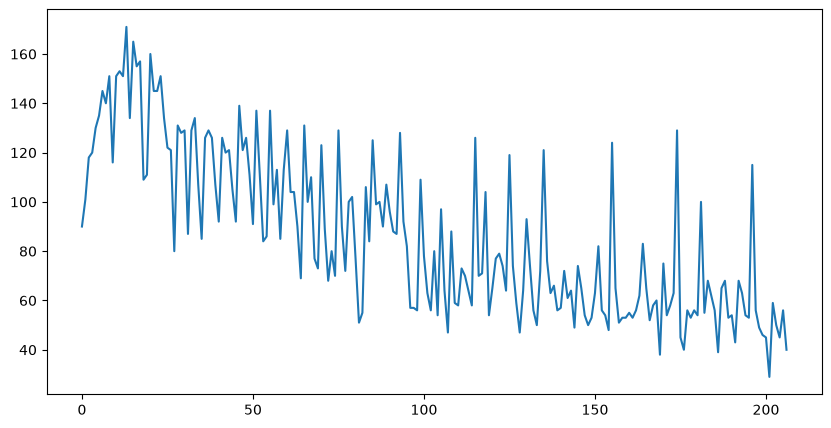

In [13]:
#売り上げのグラフ化
train["y"].plot(figsize=(10,5))

C:\Users\NDY13\AppData\Local\Temp\ipykernel_4592\3451644052.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[0][1].set_xticklabels(ax[0][1].get_xticklabels(),rotation=30)
C:\Users\NDY13\AppData\Local\Temp\ipykernel_4592\3451644052.py:7: UserWarning: Glyph 24555 (\N{CJK UNIFIED IDEOGRAPH-5FEB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\NDY13\AppData\Local\Temp\ipykernel_4592\3451644052.py:7: UserWarning: Glyph 26228 (\N{CJK UNIFIED IDEOGRAPH-6674}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\NDY13\AppData\Local\Temp\ipykernel_4592\3451644052.py:7: UserWarning: Glyph 26311 (\N{CJK UNIFIED IDEOGRAPH-66C7}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\NDY13\AppData\Local\Temp\ipykernel_4592\3451644052.py:7: UserWarning: Glyph 12428 (\N{HIRAGANA LETTER RE}) missing from font(s) DejaVu Sans.
  plt.tight_layo

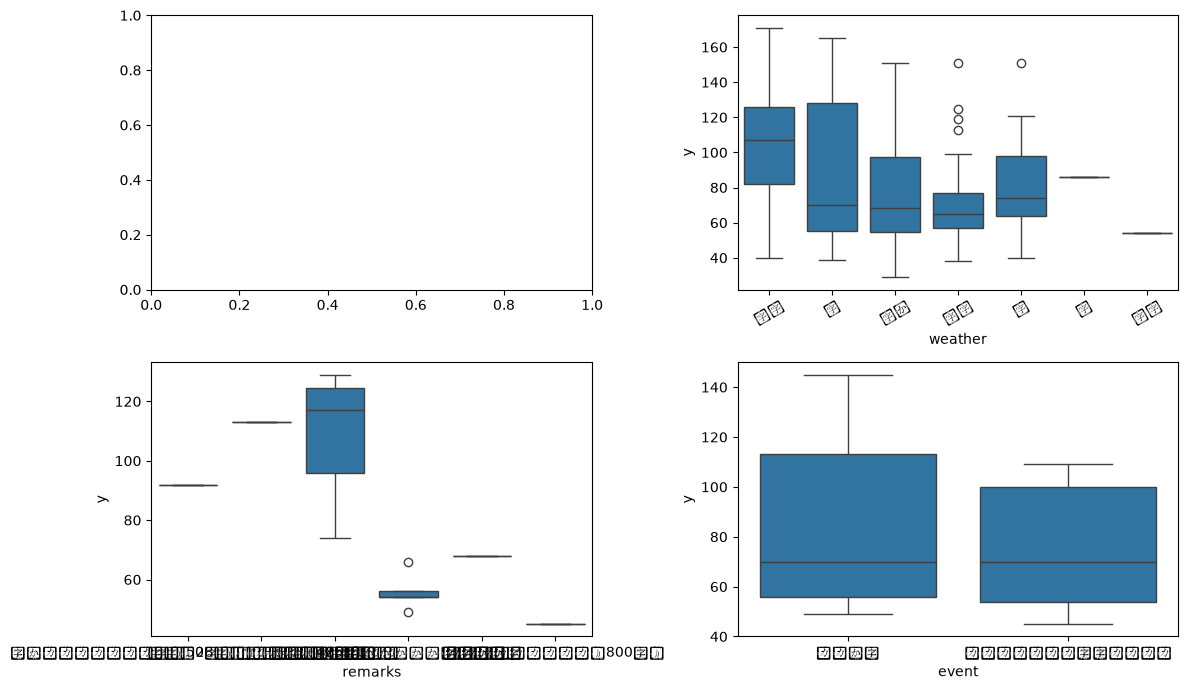

In [14]:
#グラフ化して、売り上げに影響を与える要素を確認する
fig, ax = plt.subplots(2,2,figsize=(12,7))
sns.boxplot(x="weather",y="y",data=train,ax=ax[0][1])
sns.boxplot(x="remarks",y="y",data=train,ax=ax[1][0])
ax[0][1].set_xticklabels(ax[0][1].get_xticklabels(),rotation=30)
sns.boxplot(x="event",y="y",data=train,ax=ax[1][1])
plt.tight_layout()

In [15]:
#お楽しみメニューの有無を確認する
#欠損値を「なし」に置き換える
all_data.loc[all_data["remarks"]!="お楽しみメニュー","remarks"]="なし"

In [16]:
#eventの欠損値を「なし」に置き換える
all_data["event"]=all_data["event"].fillna("なし")
all_data["event"].unique()

<StringArray>
['なし', 'ママの会', 'キャリアアップ支援セミナー']
Length: 3, dtype: str

In [17]:
#NaNの数を確認する
all_data.isnull().sum()

datetime           0
y                 40
week               0
soldout            0
name               0
kcal              45
remarks            0
event              0
payday           235
weather            0
precipitation      0
temperature        0
fig                0
dtype: int64

In [18]:
#kcalの欠損値を平均値で補完する
all_data["kcal"] = all_data["kcal"].fillna(all_data["kcal"].mean())
all_data.isnull().sum()

datetime           0
y                 40
week               0
soldout            0
name               0
kcal               0
remarks            0
event              0
payday           235
weather            0
precipitation      0
temperature        0
fig                0
dtype: int64

In [19]:
#補完の確認
all_data["kcal"].head()

0    407.381188
1    407.381188
2    407.381188
3    407.381188
4    407.381188
Name: kcal, dtype: float64

In [20]:
#paydayの有無を確認する
print(train.payday.unique())
all_data.loc[~all_data["payday"].isnull(),["week","payday"]]

[nan  1.]


,week,payday
16,火,1.0
31,金,1.0
51,月,1.0
70,月,1.0
92,木,1.0
110,金,1.0
132,火,1.0
154,木,1.0
174,金,1.0
194,水,1.0


In [21]:
#paydayの欠損値を0で補完する
all_data["payday"] = all_data["payday"].fillna(0)
all_data["payday"].unique()

array([0., 1.])

In [22]:
#降水量の前処理
# 降水量が--の時
all_data[all_data["precipitation"]=="--"]["weather"].unique()

<StringArray>
['快晴', '曇', '晴れ', '薄曇']
Length: 4, dtype: str

In [23]:
#降水量が0の時
all_data[all_data["precipitation"]=="0"]["weather"].unique()

<StringArray>
['雨', '曇', '雷電', '薄曇']
Length: 4, dtype: str

In [24]:
#降水量に数値が入っているとき
all_data[~(all_data["precipitation"]=="0") & ~(all_data["precipitation"]=="--")]["weather"].unique()


<StringArray>
['曇', '雨', '雪']
Length: 3, dtype: str

In [25]:
#precipitation_flg(カテゴリ変数)を作成する
all_data["precipitation_flg"]="悪い"
all_data.loc[(all_data["precipitation"]=="\--"),"precipitation_flg"]="良い"
all_data.loc[(all_data["precipitation"]=="0"),"precipitation_flg"]="やや悪い"


<>:3: SyntaxWarning: "\-" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\-"? A raw string is also an option.
<>:3: SyntaxWarning: "\-" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\-"? A raw string is also an option.
C:\Users\NDY13\AppData\Local\Temp\ipykernel_4592\3952447809.py:3: SyntaxWarning: "\-" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\-"? A raw string is also an option.
  all_data.loc[(all_data["precipitation"]=="\--"),"precipitation_flg"]="良い"


In [26]:
#文字列を数的データに変える（量的変数）
all_data["precipitation"] = all_data["precipitation"].replace("--",-1)

In [27]:
#欠損値がなくなったことを確認する
all_data.info()

<class 'pandas.DataFrame'>
Index: 247 entries, 0 to 39
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   datetime           247 non-null    str    
 1   y                  207 non-null    float64
 2   week               247 non-null    str    
 3   soldout            247 non-null    int64  
 4   name               247 non-null    str    
 5   kcal               247 non-null    float64
 6   remarks            247 non-null    str    
 7   event              247 non-null    str    
 8   payday             247 non-null    float64
 9   weather            247 non-null    str    
 10  precipitation      247 non-null    object 
 11  temperature        247 non-null    float64
 12  fig                247 non-null    int64  
 13  precipitation_flg  247 non-null    str    
dtypes: float64(4), int64(2), object(1), str(7)
memory usage: 28.9+ KB


In [28]:
#経過日数カラムを作成
all_data['days']=range(1,len(all_data)+1)

In [29]:
#各カラムの一意の値を知る
for col in all_data.columns:
    print(col,all_data[col].unique())
    print(all_data[col].unique())
    print("--------------------------------------------------")

datetime <StringArray>
['2013-11-18', '2013-11-19', '2013-11-20', '2013-11-21', '2013-11-22',
 '2013-11-25', '2013-11-26', '2013-11-27', '2013-11-28', '2013-11-29',
 ...
 '2014-11-14', '2014-11-17', '2014-11-18', '2014-11-19', '2014-11-20',
 '2014-11-21', '2014-11-25', '2014-11-26', '2014-11-27', '2014-11-28']
Length: 247, dtype: str
<StringArray>
['2013-11-18', '2013-11-19', '2013-11-20', '2013-11-21', '2013-11-22',
 '2013-11-25', '2013-11-26', '2013-11-27', '2013-11-28', '2013-11-29',
 ...
 '2014-11-14', '2014-11-17', '2014-11-18', '2014-11-19', '2014-11-20',
 '2014-11-21', '2014-11-25', '2014-11-26', '2014-11-27', '2014-11-28']
Length: 247, dtype: str
--------------------------------------------------
y [ 90. 101. 118. 120. 130. 135. 145. 140. 151. 116. 153. 171. 134. 165.
 155. 157. 109. 111. 160. 122. 121.  80. 131. 128. 129.  87. 107.  85.
 126.  92. 105. 139.  91. 137.  84.  86.  99. 113. 104.  69. 100. 110.
  77.  73. 123.  89.  68.  70.  72. 102.  51.  55. 106. 125.  96.  88.


In [30]:
#one-hotエンコーダー
ohe_columns = ["week","soldout","remarks","event","payday","weather","precipitation_flg"]
all_data=pd.get_dummies(all_data,dummy_na=False,columns=ohe_columns)

In [31]:
all_data[["week_月","week_火","week_水","week_木","week_金"]].head()

,week_月,week_火,week_水,week_木,week_金
0,True,False,False,False,False
1,False,True,False,False,False
2,False,False,True,False,False
3,False,False,False,True,False
4,False,False,False,False,True


In [32]:
#データをtrainとtestに分ける
train = all_data.query("fig==1")
test = all_data.query("fig==0")


In [33]:
#trainデータとtestデータの説明変数と目的変数を分ける
linear_X_train = train[["days","temperature","kcal","remarks_お楽しみメニュー","remarks_なし",
                        "week_月","week_火","week_水","week_木","week_金","weather_雨","soldout_1",
                        "precipitation_flg_やや悪い","precipitation_flg_悪い"]]


In [34]:
#目的変数はLinearとRandomForestで共通
y_train = train["y"]


In [35]:
#testデータもLinearXtrainと同じカラムにする
linear_X_test = test[["days","temperature","kcal","remarks_お楽しみメニュー","remarks_なし",
                        "week_月","week_火","week_水","week_木","week_金","weather_雨","soldout_1",
                        "precipitation_flg_やや悪い","precipitation_flg_悪い"]]


In [36]:
#LinearRegressionのパラメータ設定
linear=LR()

In [37]:
#線形回帰モデル作成
linear.fit(linear_X_train,y_train)

LinearRegression()

In [38]:
#予測
Linear_pred = linear.predict(linear_X_train)

In [39]:
#y_trainと予測値のrmseを計算する
from sklearn.metrics import mean_squared_error as MSE
print("RMSE",np.sqrt(MSE(y_train,Linear_pred)))


RMSE 16.19757657135447


<Axes: >

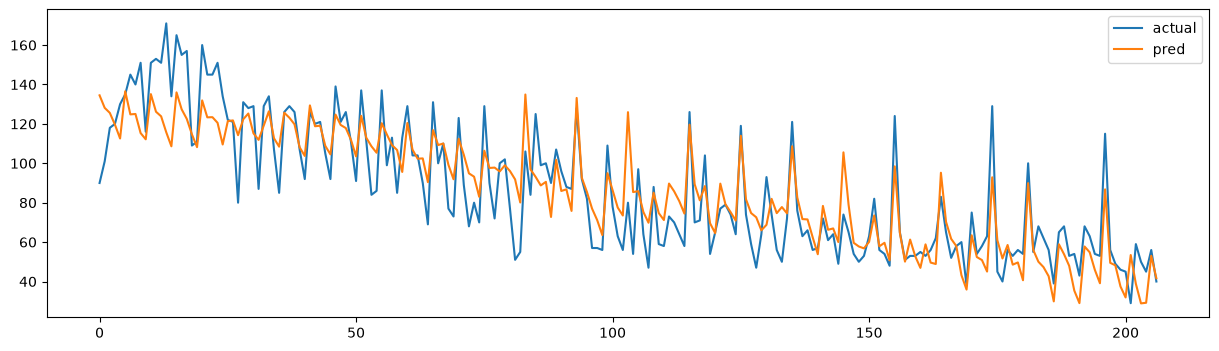

In [40]:
#線形回帰の予測値と実数値のグラフ
p = pd.DataFrame({"actual":y_train,"pred":Linear_pred})
p.plot(figsize=(15,4))

In [41]:
#RandomForestのパラメータ設定
from sklearn.ensemble import RandomForestRegressor
randomforest = RandomForestRegressor(n_estimators=100,max_depth=4,random_state=2018)


In [42]:
#残差 = 実測値-予測値を求める
pred_sub = y_train-Linear_pred


In [43]:
#RandomForestの説明変数にはすべてのカラムを使う
randomforest_X_train =train.drop(["y"],axis=1)

In [44]:
print(randomforest_X_train.dtypes)
print(pred_sub.dtype)

datetime                      str
name                          str
kcal                      float64
precipitation              object
temperature               float64
fig                         int64
days                        int64
week_月                       bool
week_木                       bool
week_水                       bool
week_火                       bool
week_金                       bool
soldout_0                    bool
soldout_1                    bool
remarks_お楽しみメニュー             bool
remarks_なし                   bool
event_なし                     bool
event_キャリアアップ支援セミナー          bool
event_ママの会                   bool
payday_0.0                   bool
payday_1.0                   bool
weather_快晴                   bool
weather_晴れ                   bool
weather_曇                    bool
weather_薄曇                   bool
weather_雨                    bool
weather_雪                    bool
weather_雷電                   bool
precipitation_flg_やや悪い       bool
precipitation_

In [45]:
#randomforest_X_trainを説明変数、pred_subを目的変数とし、モデルを作成する
randomforest_X_train = train.drop(['y','datetime'],axis=1)

In [46]:
#残差を予測するRandomForestモデルを学習
randomforest.fit(randomforest_X_train, pred_sub)

ValueError: could not convert string to float: '厚切りイカフライ'

In [ ]:
#線形回帰の予測値に、RandomForestで予測した残差を足し合わせたものを最終的な予測値とする
combined_pred =linear.predict(linear_X_train) + randomforest.predict(randomforest_X_train)

AttributeError: 'RandomForestRegressor' object has no attribute 'estimators_'

In [ ]:
#最終的な予測値を出力する
print(combined_pred)

In [ ]:
#学習用データ
#説明変数に"temperature""（温度）を利用
X_train = train['temperature']
X_train.shape

(207,)

In [ ]:
#目的変数に"y"（売上）を利用
y_train = train['y']


In [ ]:
#検証用（予測用）データ
X_test = test['temperature']

In [ ]:

#トレーニングデータとテストデータを一列データに変換
X_train = X_train.values.reshape(-1,1)
X_test = X_test.values.reshape(-1,1)


In [ ]:
#X_trainを表示
print(X_train)

[[19.8]
 [17. ]
 [15.5]
 [15.2]
 [16.1]
 [14.6]
 [17.9]
 [14.7]
 [17.7]
 [12.1]
 [13.8]
 [13.9]
 [13.5]
 [13.8]
 [14.9]
 [ 9.1]
 [ 7.1]
 [11. ]
 [12.3]
 [13.9]
 [11.3]
 [10.8]
 [ 7.8]
 [ 6.8]
 [ 8.4]
 [11.5]
 [ 8. ]
 [ 7.3]
 [ 7.3]
 [ 9.8]
 [10.9]
 [ 5.1]
 [ 5.8]
 [ 2.9]
 [ 7. ]
 [ 7.8]
 [ 6.5]
 [10.4]
 [ 7.4]
 [ 8.5]
 [10.1]
 [ 5.1]
 [12.6]
 [10.3]
 [15.3]
 [14.1]
 [15.9]
 [ 3.8]
 [ 3. ]
 [ 4.2]
 [ 5.5]
 [ 7.8]
 [ 6.3]
 [ 6.4]
 [ 1.2]
 [11.6]
 [ 6.8]
 [ 7.3]
 [ 5.4]
 [ 8.5]
 [ 6.6]
 [10.5]
 [11.5]
 [ 8.5]
 [17.7]
 [ 7.8]
 [ 8.3]
 [ 6.1]
 [ 6.7]
 [ 7. ]
 [ 7.6]
 [ 8.7]
 [14.8]
 [15.2]
 [11.5]
 [14. ]
 [18.9]
 [12.6]
 [ 7.5]
 [17.4]
 [18.9]
 [18.7]
 [12.4]
 [18.5]
 [17.5]
 [16.1]
 [18.2]
 [14.3]
 [17.8]
 [13.8]
 [20.1]
 [19. ]
 [21.3]
 [16.5]
 [16.4]
 [19.7]
 [21.5]
 [20.1]
 [11.4]
 [16.4]
 [18.8]
 [19.4]
 [19.9]
 [20.8]
 [22.7]
 [17.5]
 [24. ]
 [23.3]
 [18.9]
 [21. ]
 [23.4]
 [22.7]
 [18.6]
 [26. ]
 [19.3]
 [23.8]
 [22.8]
 [23.9]
 [17.4]
 [19. ]
 [19.8]
 [23.9]
 [23.7]
 [25.7]
 [26. ]


In [ ]:
#X_testを表示
print(X_test)

[[20.2]
 [23.9]
 [28.7]
 [21.5]
 [22.1]
 [23.3]
 [22.5]
 [26.1]
 [26.8]
 [15.6]
 [18.6]
 [23. ]
 [23.9]
 [20.2]
 [15.5]
 [14.7]
 [18.7]
 [22.7]
 [19.1]
 [19.6]
 [19.6]
 [18.8]
 [18.9]
 [16. ]
 [19.2]
 [20.1]
 [21.2]
 [14.7]
 [14.4]
 [19.5]
 [15.8]
 [14.3]
 [16.1]
 [14.9]
 [10.5]
 [14.9]
 [11.4]
 [ 9.2]
 [15.1]
 [15.3]]


In [ ]:
X_train = train['temperature']
X_train = X_train.values.reshape(-1,1)
X_train.shape


(207, 1)

In [ ]:
#モデルを代入
model = LR()


In [ ]:
#データを学習させる
model.fit(X_train,y_train)

LinearRegression()

In [ ]:
model.coef_
#傾き
model.intercept_
#切片

np.float64(134.79948383749922)

In [ ]:
#検証（決定係数の計算）
model.score(X_train,y_train)

0.42946028151941373

In [ ]:
#予測実行
X_test = test['temperature']
X_test = X_test.values.reshape(-1,1)

Linear_pred2 = model.predict(X_test)
print(Linear_pred2)

[ 84.25136537  74.99255159  62.9811175   80.99826864  79.49683938
  76.49398085  78.49588653  69.48731097  67.73564349  95.76232304
  88.25517673  77.24469548  74.99255159  84.25136537  96.01256125
  98.01446693  88.00493852  77.99541011  87.00398568  85.75279463
  85.75279463  87.75470031  87.5044621   94.7613702   86.75374747
  84.50160358  81.74898327  98.01446693  98.76518156  86.00303284
  95.26184662  99.01541977  94.51113199  97.51399051 108.52447176
  97.51399051 106.27232787 111.7775685   97.01351409  96.51303767]


In [ ]:
#サンプルを確認
sample.head()

,0,1
0,2014-10-1,24
1,2014-10-2,71
2,2014-10-3,25
3,2014-10-6,32
4,2014-10-7,60


In [ ]:
sample[1] = Linear_pred2
sample.head()

,0,1
0,2014-10-1,84.251365
1,2014-10-2,74.992552
2,2014-10-3,62.981117
3,2014-10-6,80.998269
4,2014-10-7,79.496839


In [ ]:
#sampleファイルをcsv化する
sample.to_csv('submit1.csv',index=None,header=None)